# Assignment #2: Measure Your Cameras Spatial Resolution

Alexander Matteson 10/13/2026

GitHub URL: https://github.com/AlexanderMatteson/Matteson_ee513_project1.git


In [50]:
# imports:
import rawpy
import imageio.v3 as iio
import os
import rawpy
import pandas as pd
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import cv2
from matplotlib.colors import ListedColormap
import sys
from scipy.optimize import brentq
from scipy.special import erf
import matplotlib
import psu_imaging as psu
import sys
from pathlib import Path

### Part 1: Camera Geometry

1. Calibrate your camera with cv2.calibrateCamera from at least 15 successful checkerboard detections, using the square size you measured in Exercise 1 rather than the nominal 20.0 mm. Report the focal lengths in pixels and in millimeters, the principal point, the four distortion coefficients, and the RMS reprojection error. A handheld calibration from well-located corners should give an RMS below about 1 pixel; if yours is well above that, suspect the target before you suspect your code.
Deliverable: Labeled list of the calibration parameters with units.

Size: (3024, 4032) | Pattern: RGBG
2x2 pattern:
 [[0 1]
 [3 2]]


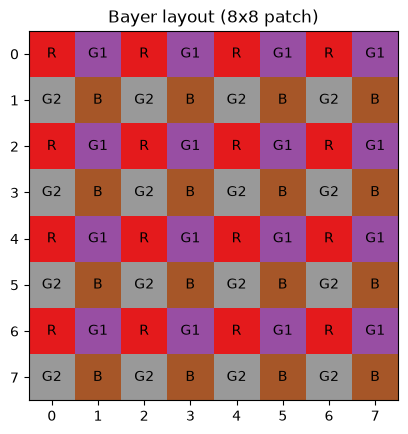

In [2]:
# we will use raw capture .dng images, instead of demosaicing them we will just use the green channel.
# in this cell lets look at that
path = r"C:\Users\ammat\OneDrive\Documents\ee513\Images\Target1.dng"

with rawpy.imread(path) as raw:
    colors = raw.raw_colors_visible          # 0=R, 1=G, 2=B, 3=G (second green)
    print("Size:", colors.shape, "| Pattern:", raw.color_desc.decode())
    print("2x2 pattern:\n", colors[:2, :2])

# zoom in on an 8x8 patch and label each pixel
patch = colors[1000:1008, 1000:1008]
names = {0: "R", 1: "G1", 2: "B", 3: "G2"}
plt.imshow(patch, cmap="Set1")
for r in range(8):
    for c in range(8):
        plt.text(c, r, names[patch[r, c]], ha="center", va="center")
plt.title("Bayer layout (8x8 patch)"); plt.show()

(1512, 2016) uint8


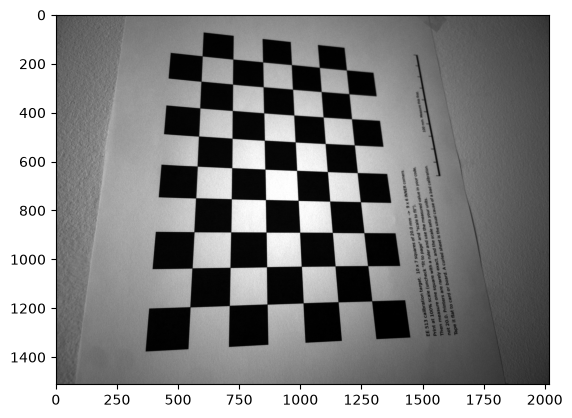

In [3]:
# fucntion to load the images and just get the green pixels

import rawpy, numpy as np

def load_green(path, as_8bit=True):
    """Raw DNG -> average of the two green sites per 2x2 block (half-size array)."""
    with rawpy.imread(path) as raw:
        bayer = raw.raw_image_visible.astype(np.float32)
        black = np.array(raw.black_level_per_channel, dtype=np.float32)
        bayer -= black[raw.raw_colors_visible]      # subtract black level per colour
    bayer = np.clip(bayer, 0, None)

    H, W = (bayer.shape[0] // 2) * 2, (bayer.shape[1] // 2) * 2   # trim to even size
    bayer = bayer[:H, :W]

    g1 = bayer[0::2, 1::2]    # G1: row 0, col 1 of each block
    g2 = bayer[1::2, 0::2]    # G2: row 1, col 0 of each block
    g = (g1 + g2) / 2.0

    if not as_8bit:
        return g
    lo, hi = np.percentile(g, 0.5), np.percentile(g, 99.5)
    return np.clip((g - lo) / (hi - lo) * 255, 0, 255).astype(np.uint8)

# quick check
path = r"C:\Users\ammat\OneDrive\Documents\ee513\Images\Target1.dng"
gray = load_green(path)
print(gray.shape, gray.dtype)

import matplotlib.pyplot as plt
plt.imshow(gray, cmap="gray"); plt.show()

In [4]:
# Load the images of the test target: these are the raw .dng images and we will use only the green channel
FOLDER = r"C:\Users\ammat\OneDrive\Documents\ee513\Images" # where are the target images?
NUM_IMGs = 15 # how many?
pattern_size = (9, 6)
SQUARE_MM = 19.0   # in mm the measured square size on the printed targets

# 3D corner positions for one board: (0,0,0), (s,0,0), (2s,0,0) ... on the Z=0 plane 
objp = np.zeros((pattern_size[0] * pattern_size[1], 3), np.float32)
objp[:, :2] = np.mgrid[0:pattern_size[0], 0:pattern_size[1]].T.reshape(-1, 2)
objp *= SQUARE_MM

criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.001)

objpoints = []   # 3D points in real-world space
imgpoints = []   # 2D points in the image plane
image_size = None

# load the images:
for i in range(NUM_IMGs):
    path = FOLDER + "\\" + f"Target{i+1}.dng"
    #print(path)
    img = load_green(path)
    image_size = img.shape[::-1]        # (width, height), needed by calibrateCamera
    #print(image_size)
    # find checkerboard corners
    ret, corners = cv2.findChessboardCorners(img, pattern_size, None)

    if ret == True:
        #print(path)
        corners = cv2.cornerSubPix(img, corners, (11, 11), (-1, -1), criteria)
        objpoints.append(objp) # saving the obj points and corners
        imgpoints.append(corners)
    else:
        print("FAILED: " + path)
    
    
# use calibrate camers
rms, mtx, dist, rvecs, tvecs = cv2.calibrateCamera(
    objpoints, imgpoints, image_size, None, None, flags=cv2.CALIB_FIX_K3)

# print the rms
print("RMS = " + str(rms))

# distortion corfficients (four)
k1, k2, p1, p2, k3 = dist.ravel()[:5] 
print("k1 = " + str(k1))
print("k2 = " + str(k2))
print("p1 = " + str(p1))
print("p2 = " + str(p2))

fx, fy = mtx[0, 0], mtx[1, 1]
cx, cy = mtx[0, 2], mtx[1, 2]

# Pixel pitch of the green array: native 1.4 um, doubled because each green
# pixel is a 2x2 block of the sensor
PIXEL_PITCH_MM = 0.00257 # <- ai search estimated thvalue for my camera *(but we calculate this below and I have updated it to the calculated value from below)

print("Array size (w, h):", image_size)
print(f"fx = {fx:.2f} px, fy = {fy:.2f} px")
print(f"fx = {fx*PIXEL_PITCH_MM:.3f} mm, fy = {fy*PIXEL_PITCH_MM:.3f} mm")
print(f"Principal point: cx = {cx:.2f} px, cy = {cy:.2f} px")

RMS = 0.4146021385713169
k1 = 0.08309975862169096
k2 = -0.1491227496686534
p1 = -0.0012237626436071018
p2 = -0.00036844270857836056
Array size (w, h): (2016, 1512)
fx = 1551.70 px, fy = 1554.49 px
fx = 3.988 mm, fy = 3.995 mm
Principal point: cx = 998.82 px, cy = 745.37 px


Thoughts going back: in the last step of this section I look up the focal length from the EXIF file and it listed focal length of 4 m. Our fx and fy being ~4 mm here should show we are on the right track

2. Undistort an image that contains a long straight edge near the boundary of the frame, where distortion is largest.
Deliverable: The original and undistorted images, side by side

Image size: (2016, 1512) | calibration size: (2016, 1512)


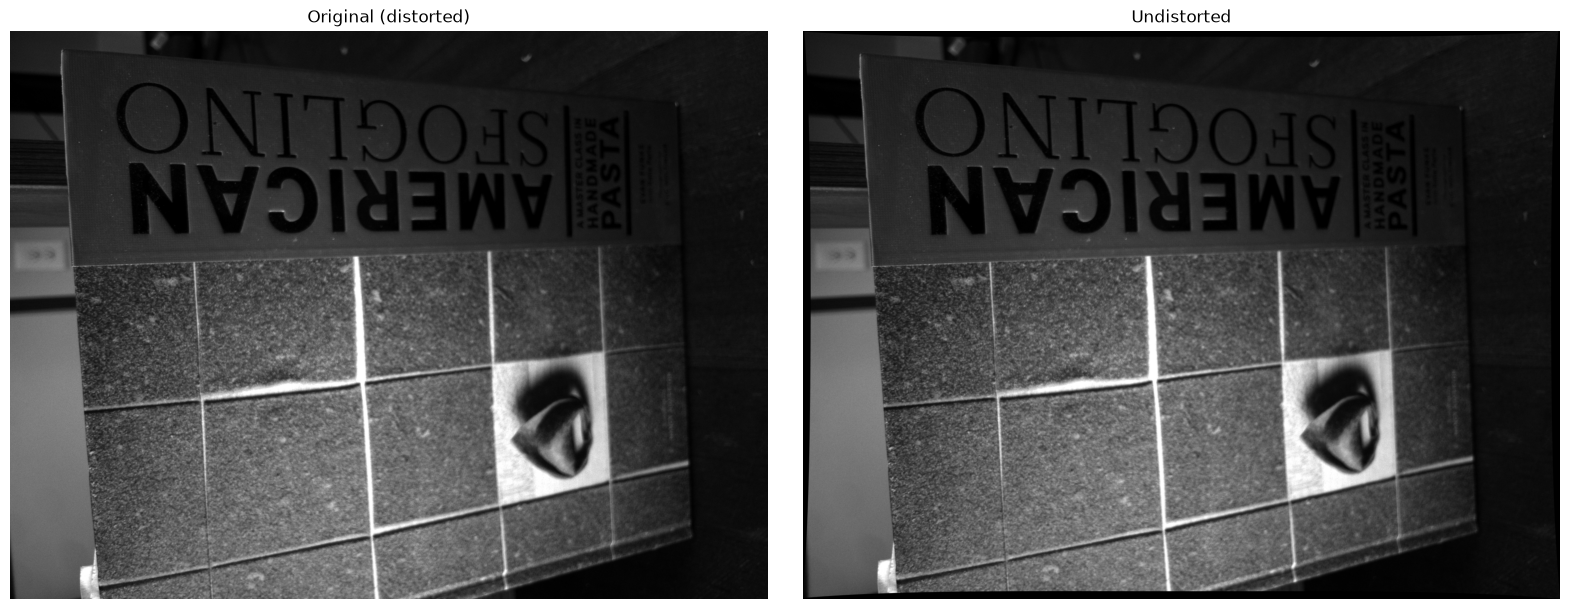

True

In [5]:
path = r"C:\Users\ammat\OneDrive\Documents\ee513\Images\IMG_0084.DNG"   # image with the long straight edge
img = load_green(path)                 # same loader as the calibration images
h, w = img.shape
print("Image size:", (w, h), "| calibration size:", image_size)   # these must match

# alpha=1 keeps every source pixel (black borders appear), so the edge near the
# frame boundary isn't cropped away. alpha=0 would crop to the valid region.
newmtx, roi = cv2.getOptimalNewCameraMatrix(mtx, dist, (w, h), alpha=1, newImgSize=(w, h))
und = cv2.undistort(img, mtx, dist, None, newmtx)

# optional: a reference straight line through two points on the edge (x, y in pixels)
# p1, p2 = (200, 80), (3800, 90)
# for im in (img, und): cv2.line(im, p1, p2, 255, 2)

# side by side
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
ax[0].imshow(img, cmap="gray");  ax[0].set_title("Original (distorted)")
ax[1].imshow(und, cmap="gray");  ax[1].set_title("Undistorted")
for a in ax: a.axis("off")
plt.tight_layout()
plt.savefig("undistort_side_by_side.png", dpi=150)
plt.show()

# also save as a single image file
cv2.imwrite("undistort_side_by_side_cv.png", np.hstack([img, und]))

Image size: (2016, 1512) | calibration size: (2016, 1512)


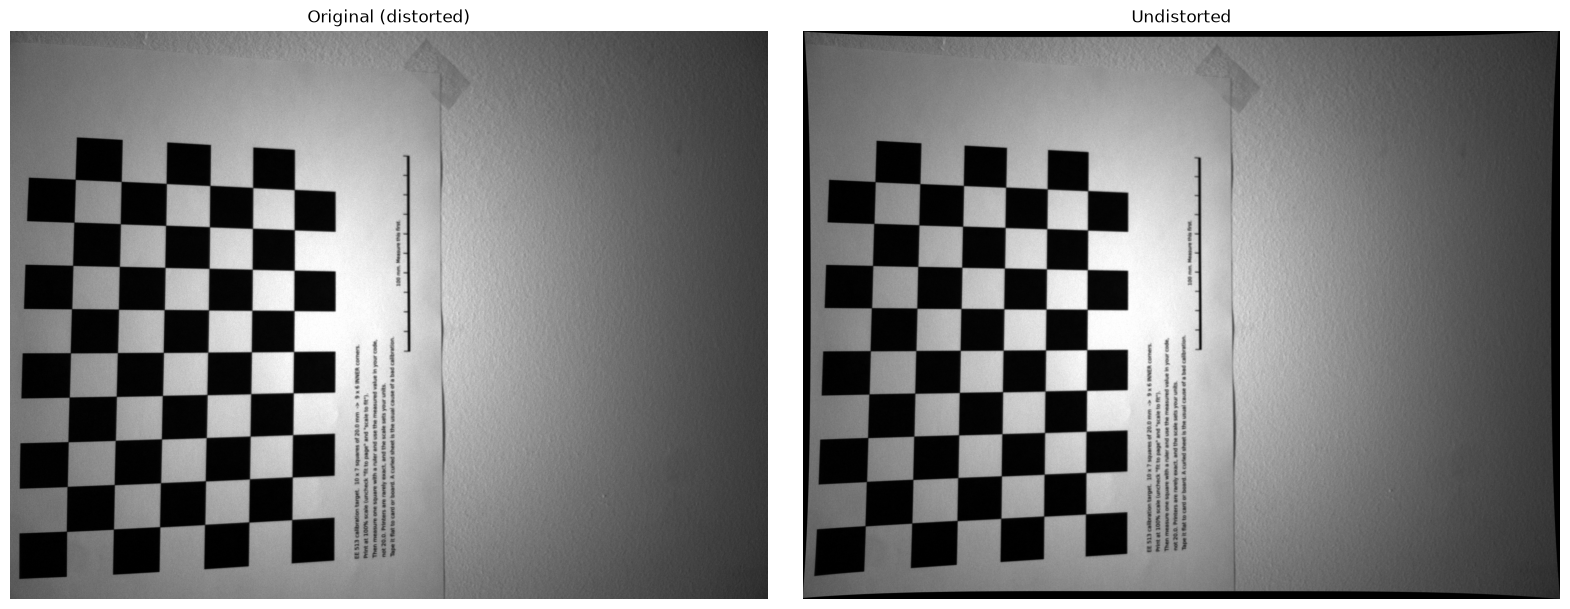

True

In [6]:
# wait maybe he meant to use one of the checkerboard images (Target7.dng has an edge near the boarder of the
# image).
path = r"C:\Users\ammat\OneDrive\Documents\ee513\Images\Target7.DNG"   # image with the long straight edge
img = load_green(path)                 # same loader as the calibration images
h, w = img.shape
print("Image size:", (w, h), "| calibration size:", image_size)   # these must match

# alpha=1 keeps every source pixel (black borders appear), so the edge near the
# frame boundary isn't cropped away. alpha=0 would crop to the valid region.
newmtx, roi = cv2.getOptimalNewCameraMatrix(mtx, dist, (w, h), alpha=1, newImgSize=(w, h))
und = cv2.undistort(img, mtx, dist, None, newmtx)

# optional: a reference straight line through two points on the edge (x, y in pixels)
# p1, p2 = (200, 80), (3800, 90)
# for im in (img, und): cv2.line(im, p1, p2, 255, 2)

# side by side
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
ax[0].imshow(img, cmap="gray");  ax[0].set_title("Original (distorted)")
ax[1].imshow(und, cmap="gray");  ax[1].set_title("Undistorted")
for a in ax: a.axis("off")
plt.tight_layout()
plt.savefig("undistort_side_by_side.png", dpi=150)
plt.show()

# also save as a single image file
cv2.imwrite("undistort_side_by_side_cv.png", np.hstack([img, und]))


Ok using the checker board image you can kind of appreciate some distoation and correction around the edges.

3. Quantify that correction. Fit a straight line through one row of detected checkerboard corners and report the maximum perpendicular deviation of those corners from the fitted line, in pixels, before and after undistortion.
Deliverable: Two deviation values in pixels.

In [7]:


path = r"C:\Users\ammat\OneDrive\Documents\ee513\Images\Target7.dng"   # board with a row in the bottom-left
img = load_green(path)
h, w = img.shape

ret, corners = cv2.findChessboardCorners(img, pattern_size, None)
assert ret, "corners not found"
corners = cv2.cornerSubPix(img, corners, (11, 11), (-1, -1), criteria)

# corners come back row by row: shape (rows, cols, 2) = (6, 9, 2)
grid = corners.reshape(pattern_size[1], pattern_size[0], 2)

# undistort the same points (P=newmtx matches the undistorted image from before)
newmtx, roi = cv2.getOptimalNewCameraMatrix(mtx, dist, (w, h), alpha=1, newImgSize=(w, h))
und_corners = cv2.undistortPoints(corners, mtx, dist, P=newmtx)
und_grid = und_corners.reshape(pattern_size[1], pattern_size[0], 2)

def max_perp_dev(pts):
    """Fit a line (total least squares) and return the max perpendicular distance in px."""
    pts = pts.reshape(-1, 2).astype(np.float64)
    c = pts.mean(axis=0)
    _, _, vt = np.linalg.svd(pts - c)
    normal = vt[1]                      # unit vector perpendicular to the best-fit line
    return np.abs((pts - c) @ normal).max()

# which row is bottom-left? print each row's mean position (x, y); y grows downward
for r in range(grid.shape[0]):
    print(f"row {r}: mean (x, y) = {grid[r].mean(axis=0).round(0)}   "
          f"before = {max_perp_dev(grid[r]):.3f} px, after = {max_perp_dev(und_grid[r]):.3f} px")

ROW = 0    # <- set to the row nearest the bottom-left corner (largest y, smallest x)
before = max_perp_dev(grid[ROW])
after = max_perp_dev(und_grid[ROW])
print(f"\nRow {ROW}: max perpendicular deviation  before = {before:.3f} px,  after = {after:.3f} px")

row 0: mean (x, y) = [162. 861.]   before = 1.211 px, after = 0.126 px
row 1: mean (x, y) = [287. 860.]   before = 0.257 px, after = 0.205 px
row 2: mean (x, y) = [408. 860.]   before = 0.649 px, after = 0.195 px
row 3: mean (x, y) = [527. 859.]   before = 0.888 px, after = 0.227 px
row 4: mean (x, y) = [642. 859.]   before = 0.965 px, after = 0.173 px
row 5: mean (x, y) = [755. 858.]   before = 1.053 px, after = 0.327 px

Row 0: max perpendicular deviation  before = 1.211 px,  after = 0.126 px


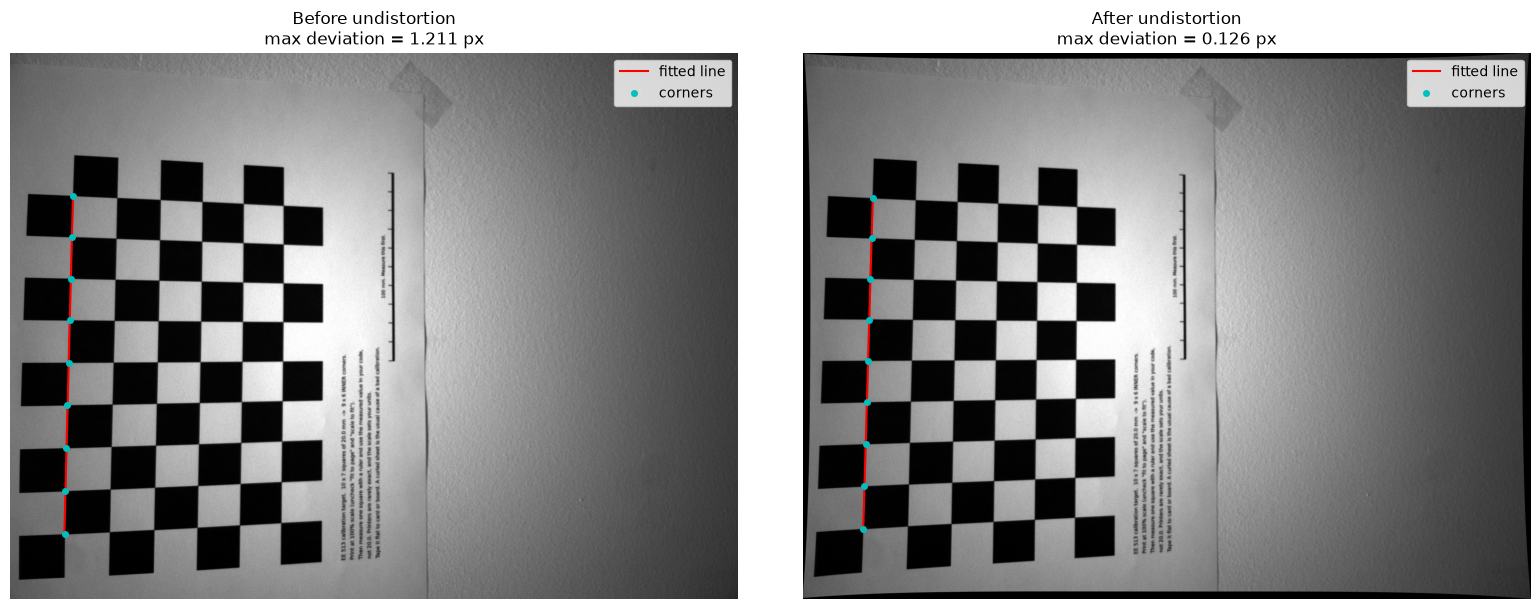

Max perpendicular deviation: before = 1.211 px, after = 0.126 px


In [8]:
und = cv2.undistort(img, mtx, dist, None, newmtx)

def fit_line(pts):
    """Total-least-squares line: returns points, centroid, unit direction, signed perpendicular distances."""
    pts = pts.reshape(-1, 2).astype(np.float64)
    c = pts.mean(axis=0)
    _, _, vt = np.linalg.svd(pts - c)
    direction, normal = vt[0], vt[1]
    return pts, c, direction, (pts - c) @ normal

def line_ends(pts, c, d):
    t = (pts - c) @ d
    return np.array([c + t.min() * d, c + t.max() * d])

pb, cb, db, resid_b = fit_line(grid[ROW])
pa, ca, da, resid_a = fit_line(und_grid[ROW])

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
for a, im, pts, c, d, title, dev in [
        (ax[0], img, pb, cb, db, "Before undistortion", resid_b),
        (ax[1], und, pa, ca, da, "After undistortion", resid_a)]:
    a.imshow(im, cmap="gray")
    ends = line_ends(pts, c, d)
    a.plot(ends[:, 0], ends[:, 1], "r-", lw=1.5, label="fitted line")
    a.plot(pts[:, 0], pts[:, 1], "c.", ms=8, label="corners")
    a.set_title(f"{title}\nmax deviation = {np.abs(dev).max():.3f} px")
    a.legend(loc="upper right")
    a.axis("off")

plt.tight_layout()
plt.savefig("row_line_fit_before_after.png", dpi=150)
plt.show()

print(f"Max perpendicular deviation: before = {np.abs(resid_b).max():.3f} px, after = {np.abs(resid_a).max():.3f} px")

4. Compute your pixel pitch in micrometers as 1000 fmm / fpx, where fmm is the focal length recorded in the EXIF metadata and fpx is the mean of the two focal lengths in pixels from item 1. Then obtain it a second way, by a route that does not use your calibration at all: divide the 35 mm equivalent focal length in the EXIF by the actual focal length to get the crop factor, divide the 43.3 mm diagonal of 35 mm film by the crop factor to get your sensor diagonal, and divide that by the image diagonal in pixels. Everything in Part 2 rests on this number, and the second route is the only warning you will get that the first one is wrong.
Deliverable: Both pitch values in micrometers, their percentage difference, and a statement of which you will use in Part 2 and why (2–3 sentences).

Definition: EXIF = Exchangeable Image File Format, has meta data about the image.

In [9]:
# from the dng files properties:
f_mm = 4 # mm
f_35mm = 26

# method 1:
fpx = (mtx[0, 0] + mtx[1, 1]) / 2          # mean of fx and fy, px
pitch1_um = 1000 * f_mm / fpx              # micrometers per pixel

# method 2: 
crop = f_35mm / f_mm                       # crop factor
sensor_diag_mm = 43.3 / crop               # physical sensor diagonal, mm
w, h = image_size                          # the green-array size you calibrated at
img_diag_px = np.hypot(w, h)
pitch2_um = 1000 * sensor_diag_mm / img_diag_px

pct_diff = 100 * (pitch1_um - pitch2_um) / pitch2_um
print(f"Pitch from calibration (route 1): {pitch1_um:.3f} um")
print(f"Pitch from crop factor (route 2): {pitch2_um:.3f} um")
print(f"Difference: {pct_diff:+.2f} % (route 1 relative to route 2)")

Pitch from calibration (route 1): 2.576 um
Pitch from crop factor (route 2): 2.643 um
Difference: -2.57 % (route 1 relative to route 2)


The values for both methods are very similar, with a percent difference of -2.57%, I believes that this shows we do not have any major errors in our method. Going forward I will plan to use the route 1. Route 1 this is based on our calibration for the camera where as route two is from the EXIF specs and I don't know how this was estiated or rounded. 

### Part 2: Predicted Response

Note: because I'm taking the green pixels from the 2x2 bayer mosaic and using that array in the calibrations, everything is actually for a 2 pixel width (we take 1 value for each 2x2 r,g,b mosaic). So I need to actually devide the pitch from the above calibration by 2. So the 2.576 um/2 = 1.288 um is what we will use.

5. Compute the diffraction cutoff νc, the green-plane Nyquist frequency, and the ratio of the two.
Deliverable: Three values, each in cycles per micrometer and in cycles per millimeter.

In [20]:
lam = 0.55                     # um
N = 1.6                        # <- from your EXIF F-number

p = 1.288                      # um

nu_c = 1 / (lam * N)           # diffraction cutoff, cycles/um
nu_nyq = 1 / (4 * p)           # green-plane Nyquist (sample spacing 2p), cycles/um
ratio = nu_c / nu_nyq          # dimensionless

print("diffraction cutoff νc = " + str(nu_c) + " cycles/um")
print("green-plane Nyquist frequency = " + str(nu_nyq) + " cycles/um")
print("diffraction cutoff νc = " + str(nu_c*1000) + " cycles/m")
print("green-plane Nyquist frequency = " + str(nu_nyq*1000) + " cycles/m")

print("The ratio: " + str(ratio))

diffraction cutoff νc = 1.1363636363636362 cycles/um
green-plane Nyquist frequency = 0.19409937888198758 cycles/um
diffraction cutoff νc = 1136.3636363636363 cycles/m
green-plane Nyquist frequency = 194.09937888198758 cycles/m
The ratio: 5.854545454545454


6. State whether diffraction or sampling is the binding limit for your camera, and find the f-number at which that answer would change by setting the diffraction cutoff equal to the full-sensor Nyquist frequency 1/(2p) and solving for N.
Deliverable: The crossover f-number and a written explanation (2–4 sentences).

The current lens f stop of f/1.6 gives allows much high frequency than we can dectect with the sampling without aliasing, so it is the sampling that is our binding limit. 

In [10]:
# determine the f-number where this chnages:
lam, p = 0.55, 1.288          # um
N_crit = 2 * p / lam          # cutoff = full-sensor Nyquist 1/(2p)
print(f"N = {N_crit:.2f}, cutoff = Nyquist = {1/(2*p):.4f} cycles/um = {1000/(2*p):.1f} cycles/mm")

N = 4.68, cutoff = Nyquist = 0.3882 cycles/um = 388.2 cycles/mm


7. Plot MTFd(ν), MTFp(ν), and their product from zero to νc, with a vertical line marking the green-plane Nyquist frequency. Report the value of the product at that frequency.
Deliverable: Figure with labeled axes, and the predicted modulation at Nyquist.

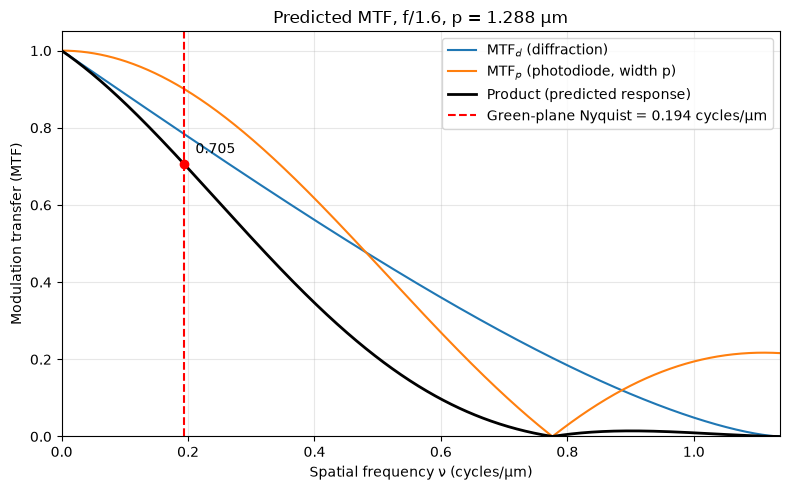

At Nyquist (0.1941 cycles/um = 194.1 cycles/mm):
  MTFd = 0.784, MTFp = 0.900, product = 0.705


In [11]:


lam = 0.55                  # um
N = 1.6                     # <- your EXIF f-number
p = 2.576 / 2               # um, native photodiode pitch (array pitch / 2)

nu_c = 1 / (lam * N)        # diffraction cutoff, cycles/um
nu_nyq = 1 / (4 * p)        # green-plane Nyquist, cycles/um

def mtf_diff(nu):
    s = np.clip(nu / nu_c, 0, 1)
    return (2 / np.pi) * (np.arccos(s) - s * np.sqrt(1 - s**2))

def mtf_pix(nu):
    return np.abs(np.sinc(nu * p))

nu = np.linspace(0, nu_c, 1000)
md, mp = mtf_diff(nu), mtf_pix(nu)
prod = md * mp

at_nyq = mtf_diff(nu_nyq) * mtf_pix(nu_nyq)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(nu, md, label="MTF$_d$ (diffraction)")
ax.plot(nu, mp, label="MTF$_p$ (photodiode, width p)")
ax.plot(nu, prod, "k", lw=2, label="Product (predicted response)")
ax.axvline(nu_nyq, color="r", ls="--", label=f"Green-plane Nyquist = {nu_nyq:.3f} cycles/µm")
ax.plot(nu_nyq, at_nyq, "ro")
ax.annotate(f"{at_nyq:.3f}", (nu_nyq, at_nyq), textcoords="offset points", xytext=(8, 8))
ax.set_xlabel("Spatial frequency ν (cycles/µm)")
ax.set_ylabel("Modulation transfer (MTF)")
ax.set_title(f"Predicted MTF, f/{N}, p = {p:.3f} µm")
ax.set_xlim(0, nu_c); ax.set_ylim(0, 1.05)
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.savefig("predicted_mtf.png", dpi=150)
plt.show()

print(f"At Nyquist ({nu_nyq:.4f} cycles/um = {nu_nyq*1000:.1f} cycles/mm):")
print(f"  MTFd = {mtf_diff(nu_nyq):.3f}, MTFp = {mtf_pix(nu_nyq):.3f}, product = {at_nyq:.3f}")

8. Determine the frequency at which the predicted response falls to 0.5, which is your predicted MTF50. If it lies above the Nyquist frequency, explain what that implies about aliasing and about which physical effect will actually set the MTF50 you measure in Part 4.
Deliverable: Predicted MTF50 in cycles per micrometer, and a written interpretation (2–4 sentences).

So we are looking for where the product of the MTD_p and MTF_p is equal to 0.5:

In [12]:
#code - make a function for the system MTF response, then use a root finder for where the response falls bellow 0.5
lam, N = 0.55, 1.6            # N: your EXIF f-number
p = 2.576 / 2                 # um, native photodiode pitch
nu_c = 1 / (lam * N)
nu_nyq = 1 / (4 * p)

def prod(nu):
    s = np.clip(nu / nu_c, 0, 1)
    md = (2 / np.pi) * (np.arccos(s) - s * np.sqrt(1 - s**2))
    return md * np.abs(np.sinc(nu * p))

# product starts at 1 and falls monotonically to 0 at nu_c, so a root exists in (0, nu_c)
mtf50 = brentq(lambda v: prod(v) - 0.5, 1e-6, nu_c)

print(f"MTF50 = {mtf50:.4f} cycles/um = {mtf50*1000:.1f} cycles/mm")
print(f"MTF50 / Nyquist = {mtf50 / nu_nyq:.2f}")

MTF50 = 0.3087 cycles/um = 308.7 cycles/mm
MTF50 / Nyquist = 1.59


First, the above value we can also find from looking at the plot above and it jsut about matches the value we calculate here. This MTF50 is at a spatial frequancy above the nyquist (0.307 cycles/um vs nyquist of 0.194 cycles/um). This should mean that we will see ailising beyond a spatial frequency of 0.307 cycles/um and this will mean that those frequencies will essentially wrap back on themselves. For what this says about what will effect the MTF50 that we will measure, I believe that this means that we will primarily be effectd by the sampling and ailising. We may also be effected by lens aberations.

### Part 3: Validating the Measurement

9. Generate a synthetic slanted edge by tilting a step edge 5 degrees, convolving it with a Gaussian point spread function of standard deviation 1.0 pixel, and sampling the result on a pixel grid.
Deliverable: Image of the simulated capture.

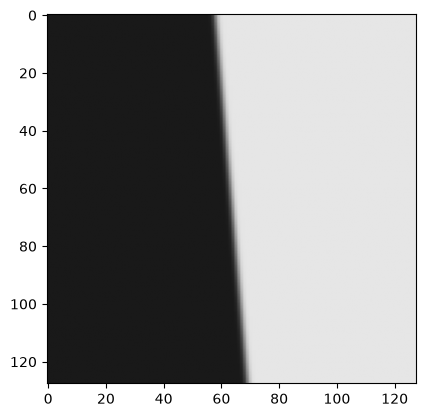

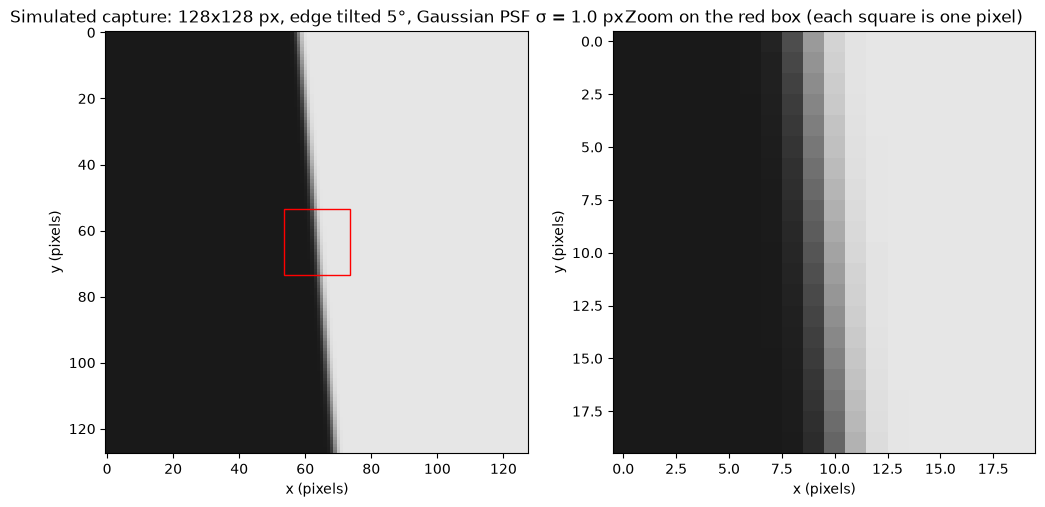

In [92]:
# 1: generate a synthetic edge (tilt a step edge by 5 degrees)
W = H = 128            # image size in pixels
theta = np.deg2rad(5)  # tilt of the edge from vertical
sigma = 1.0            # Gaussian PSF standard deviation, pixels
dark, bright = 0.1, 0.9
 
# pixel-centre coordinates, origin at the image centre
x, y = np.meshgrid(np.arange(W) - (W - 1) / 2, np.arange(H) - (H - 1) / 2)
 
# signed perpendicular distance from each pixel centre to the tilted edge line
d = x * np.cos(theta) - y * np.sin(theta)

# 2: convolve with a gaussian blur
img = dark + (bright - dark) * 0.5 * (1 + erf(d / (sigma * np.sqrt(2))))

plt.imshow(img, cmap="gray", vmin=0, vmax=1)
plt.show()

# add a zoomed in figure of the line to appreciate the blur
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(img, cmap="gray", vmin=0, vmax=1)
ax[0].set_title(f"Simulated capture: {W}x{H} px, edge tilted 5°, Gaussian PSF σ = {sigma} px")
r = (slice(54, 74), slice(54, 74))
ax[0].add_patch(plt.Rectangle((54 - .5, 54 - .5), 20, 20, fill=False, ec="r"))
ax[1].imshow(img[r], cmap="gray", vmin=0, vmax=1, interpolation="nearest")
ax[1].set_title("Zoom on the red box (each square is one pixel)")
for a in ax:
    a.set_xlabel("x (pixels)"); a.set_ylabel("y (pixels)")


10. Measure the modulation transfer function of that simulated capture with the code you will use on your own photographs.
Deliverable: Figures of the edge spread function, the line spread function, and the modulation transfer function.

from class slides steps to measure MTF of slanted line:

1. Capture a slanted edge, linear (raw, or undo the gamma first) <- use our simulated edge for this step (img)
2. Find the edge position in each row to sub-pixel precision
3. Fit a line through those positions, so one bad row cannot hurt you
4. Project every pixel onto the edge normal, bin at about 1/4 pixel
5. That is the edge spread function; differentiate it for the line spread
function
6. Window it, take the magnitude of its Fourier transform, normalize to 1
at DC
That is the MTF.

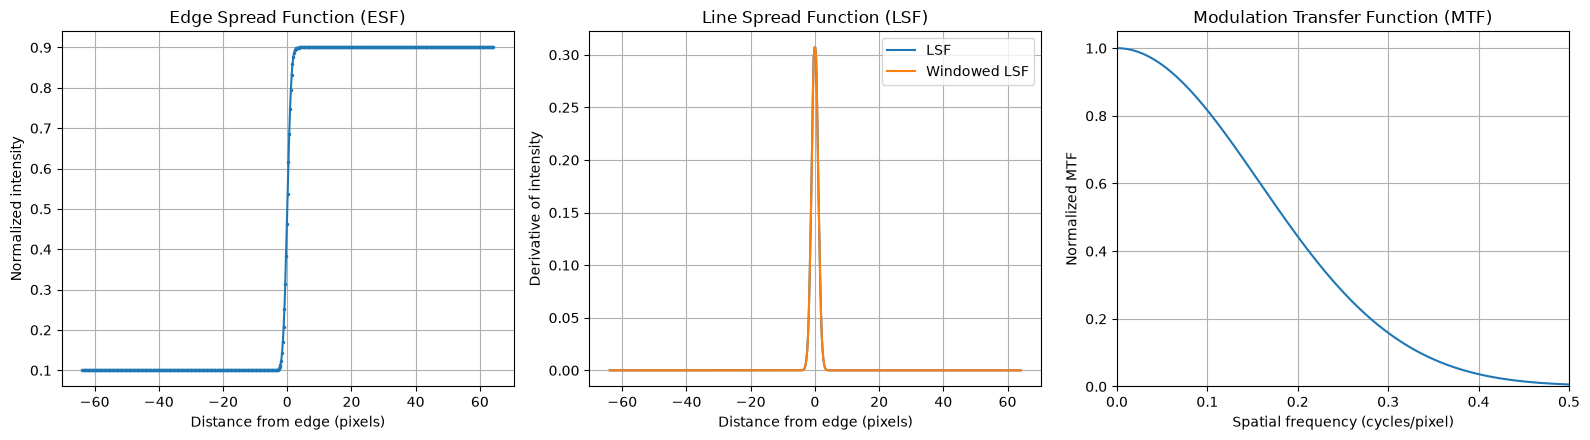

In [93]:
from scipy.stats import theilslopes
from scipy.signal import windows

# define a function to get the MTF of a slanted line:
#def slanted_MTF(img, window = 8.0):

# 1. image of slanted edge:

img = img # this is the image of the slanted edge

# 2. find the edge in the img

def FindEdges(img):
    ncols, nrows = img.shape[:2]
    edge_rows = []
    edge_cols = []
    
    for y in range(nrows):
        row = img[y, :]
    
        # First derivative along the horizontal direction.
        grad = np.gradient(row)
    
        # Find the strongest edge in this row.
        # Use absolute gradient to support either edge polarity.
        x_peak = np.argmax(np.abs(grad))
    
        # Subpixel peak localization using a parabolic fit.
        # Fit the peak and its two neighboring samples.
        if 0 < x_peak < ncols - 1:
            g = np.abs(grad)
            left = g[x_peak - 1]
            center = g[x_peak]
            right = g[x_peak + 1]
    
            denom = left - 2 * center + right
    
            if abs(denom) > 1e-12:
                offset = 0.5 * (left - right) / denom
                offset = np.clip(offset, -1, 1)
                x_subpixel = x_peak + offset
            else:
                x_subpixel = float(x_peak)
        else:
            x_subpixel = float(x_peak)
    
        edge_rows.append(y)
        edge_cols.append(x_subpixel)

    edge_rows = np.asarray(edge_rows, dtype=float)
    edge_cols = np.asarray(edge_cols, dtype=float)
    return edge_rows, edge_cols

edge_rows, edge_cols = FindEdges(img)

# 3. fit a line through that edge points
# Model: x_edge = slope * y + intercept
slope, intercept, _, _ = theilslopes(edge_cols, edge_rows) # use edge points for the 

fitted_cols = slope * edge_rows + intercept

#print(f"Edge slope (pixels/pixel): {slope:.6f}")
#print(f"Edge intercept (pixels): {intercept:.3f}")
# uncomment to see the fitted line (good check)
#plt.figure(figsize=(7, 5))
#plt.imshow(img, cmap="gray", origin="upper")
#plt.plot(edge_cols, edge_rows, ".", markersize=2,
#         label="Detected edge positions")
#plt.plot(fitted_cols, edge_rows, "r-", linewidth=2,
#         label="Robust line fit")
#plt.xlabel("Column (pixels)")
#plt.ylabel("Row (pixels)")
#plt.title("Slanted-edge detection")
#plt.legend()
#plt.tight_layout()
#plt.show()

# 4. Project every pixel onto the edge normal -> edge spread function
# The fitted edge is x = slope*y + intercept.
# Signed perpendicular distance from each pixel to the edge:
# d = (x - slope*y - intercept) / sqrt(1 + slope**2)

yy, xx = np.indices(img.shape, dtype=float)

distance = (
    xx - slope * yy - intercept
) / np.sqrt(1 + slope**2)

# Oversampling factor: 4 means 0.25 pixel per bin.
oversampling = 4
bin_width = 1.0 / oversampling

# Keep the full available distance range.
d_min = np.floor(distance.min() / bin_width) * bin_width
d_max = np.ceil(distance.max() / bin_width) * bin_width

bin_edges = np.arange(
    d_min, d_max + bin_width * 1.01, bin_width
)

# Bin centers.
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

# Average image intensity within each distance bin.
bin_index = np.digitize(distance.ravel(), bin_edges) - 1

valid = (
    (bin_index >= 0) &
    (bin_index < len(bin_centers))
)

intensity_sum = np.bincount(
    bin_index[valid],
    weights=img.ravel()[valid],
    minlength=len(bin_centers)
)

pixel_count = np.bincount(
    bin_index[valid],
    minlength=len(bin_centers)
)

esf = np.full(len(bin_centers), np.nan)
occupied = pixel_count > 0
esf[occupied] = intensity_sum[occupied] / pixel_count[occupied]

# Remove empty bins, if any.
esf = esf[occupied]
esf_x = bin_centers[occupied]

# 5. differentiate the edge spread function to get the line spread function
# Estimate the edge center from the steepest part of the ESF
edge_center = esf_x[np.argmax(np.abs(np.gradient(esf, esf_x)))]

# Restrict the ESF to a region around the edge
# The default is half the smaller image dimension on either side
half_width = min(nrows, ncols) / 2
roi = np.abs(esf_x - edge_center) <= half_width

esf_roi_x = esf_x[roi]
esf_roi = esf[roi]

# Fill any remaining gaps by interpolation
finite = np.isfinite(esf_roi)
esf_roi = np.interp(
    esf_roi_x,
    esf_roi_x[finite],
    esf_roi[finite]
)

# LSF = derivative of ESF
lsf = np.gradient(esf_roi, bin_width)

# Window: Apply a Hann window to the LSF
# This reduces spectral leakage from finite profile length
window = windows.hann(len(lsf), sym=True)
lsf_windowed = lsf * window

# 6. Take the fourier trandform of the LTF and keep the amplitude part (the MTF)
# rember: normalize to 1 at DC

# Zero-padding interpolates the displayed frequency curve;
# it does not improve the underlying measurement resolution.
n_fft = 8 * len(lsf_windowed)

fft_lsf = np.fft.rfft(lsf_windowed, n=n_fft)
mtf = np.abs(fft_lsf)

# Frequency axis in cycles per pixel.
freq = np.fft.rfftfreq(n_fft, d=bin_width)

# Normalize so that MTF(0) = 1.
if mtf[0] > 0:
    mtf /= mtf[0]

# Only display frequencies up to the original image Nyquist limit.
nyquist = 0.5
keep = freq <= nyquist

freq_plot = freq[keep]
mtf_plot = mtf[keep]

# Make PLOTS of the MTF, ESF, LSF
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].plot(esf_roi_x, esf_roi, ".-", markersize=3)
axes[0].set_title("Edge Spread Function (ESF)")
axes[0].set_xlabel("Distance from edge (pixels)")
axes[0].set_ylabel("Normalized intensity")
axes[0].grid(True)

axes[1].plot(esf_roi_x, lsf, label="LSF")
axes[1].plot(esf_roi_x, lsf_windowed, label="Windowed LSF")
axes[1].set_title("Line Spread Function (LSF)")
axes[1].set_xlabel("Distance from edge (pixels)")
axes[1].set_ylabel("Derivative of intensity")
axes[1].legend()
axes[1].grid(True)

axes[2].plot(freq_plot, mtf_plot)
axes[2].set_title("Modulation Transfer Function (MTF)")
axes[2].set_xlabel("Spatial frequency (cycles/pixel)")
axes[2].set_ylabel("Normalized MTF")
axes[2].set_xlim(0, nyquist)
axes[2].set_ylim(bottom=0)
axes[2].grid(True)

plt.tight_layout()
plt.show()

11. Compare the MTF50 your code reports against the analytic value above.
Deliverable: Measured MTF50, analytic MTF50, and the percentage error.

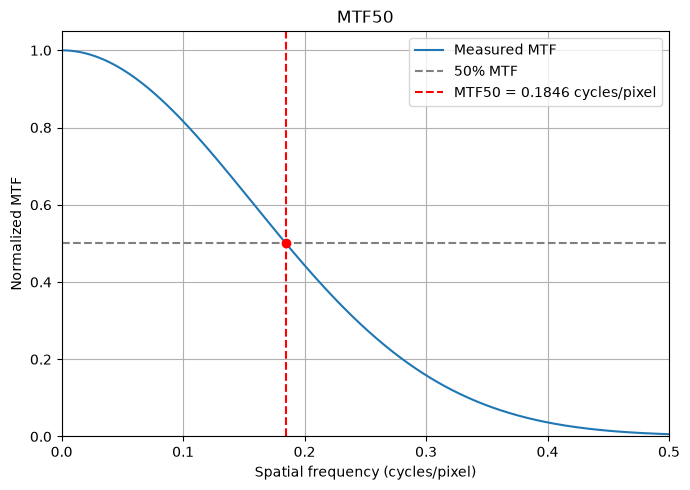

The analytic MTF50 = 0.1874 cycles per pixel
The measured MTF50 = 0.1846 cycles/pixel
The percent error = 0.01469595464946724


In [49]:
# code to get the MTF50 from our simulated image and calculation of the MTF above:
import numpy as np
import matplotlib.pyplot as plt

# Find the first frequency where MTF <= 0.5
crossings = np.where(mtf_plot <= 0.5)[0]

if len(crossings) == 0:
    mtf50 = np.nan
    print("MTF50 was not reached in the measured frequency range.")
elif crossings[0] == 0:
    mtf50 = freq_plot[0]
else:
    # Linear interpolation between adjacent samples
    i = crossings[0]

    f1, f2 = freq_plot[i - 1], freq_plot[i]
    m1, m2 = mtf_plot[i - 1], mtf_plot[i]

    mtf50 = f1 + (0.5 - m1) * (f2 - f1) / (m2 - m1)

    

# Mark MTF50 on the plot
if np.isfinite(mtf50):
    plt.figure(figsize=(7, 5))
    plt.plot(freq_plot, mtf_plot, label="Measured MTF")
    plt.axhline(0.5, color="gray", linestyle="--", label="50% MTF")
    plt.axvline(mtf50, color="red", linestyle="--",
                label=f"MTF50 = {mtf50:.4f} cycles/pixel")
    plt.scatter([mtf50], [0.5], color="red", zorder=3)

    plt.xlabel("Spatial frequency (cycles/pixel)")
    plt.ylabel("Normalized MTF")
    plt.title("MTF50")
    plt.xlim(0, 0.5)
    plt.ylim(0, 1.05)
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

# Analytic result:
sigma = 1
def analytic_mtf50(sigma):
    return np.sqrt(np.log(2) / (2 * np.pi ** 2 * sigma ** 2))
print(f"The analytic MTF50 = {analytic_mtf50(sigma):.4f} cycles per pixel")
print(f"The measured MTF50 = {mtf50:.4f} cycles/pixel")
# percent error:
MTF50_sim = mtf50
error_percent = abs(MTF50_sim-0.1874)/0.1874
print("The percent error = " + str(error_percent))

### Part 4: Measurement

12. Print the slanted edge target, tape it flat, and illuminate it evenly and off axis so that no specular highlight falls on an edge. Capture it at least five times in raw at 1x, without moving the target between captures.
Deliverable: Contact sheet of the captures.

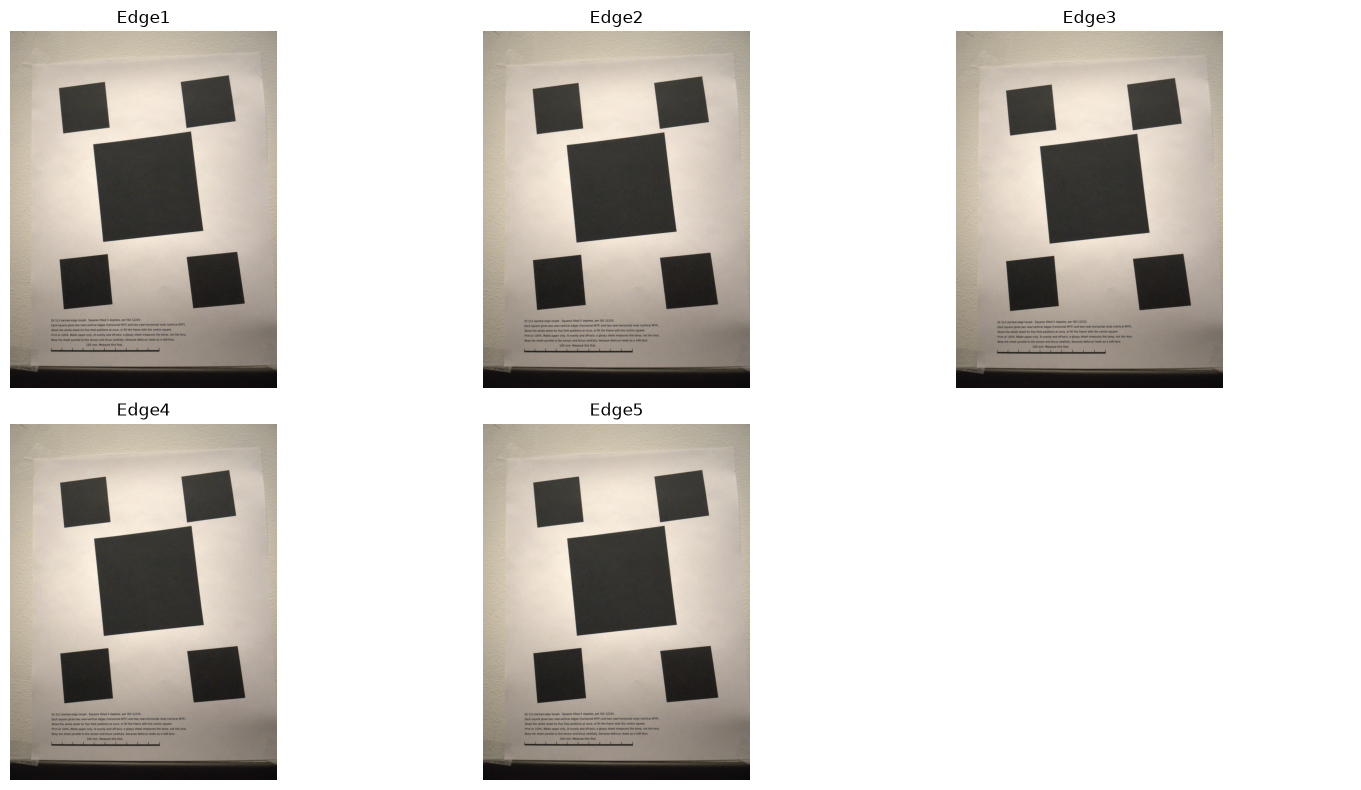

In [55]:
# load .dng raw captures and make contact sheet 

FOLDER = r"C:\Users\ammat\OneDrive\Documents\ee513\Images"
NAMES = [f"Edge{i}" for i in range(1, 6)]   # Edge1 ... Edge5
THUMB_MAX = 800                             # longest side of each thumbnail (px)
COLS = 3                                    # columns in the contact sheet
 
 
def load_dng(path, max_side=THUMB_MAX): #<- don't use this later (we dont want to demosaic) fine now to view
    """Demosaic a DNG to an 8-bit RGB array, downsized for display."""
    with rawpy.imread(path) as raw:
        rgb = raw.postprocess(
            use_camera_wb=True,
            half_size=True,        # fast: skips full-res demosaic
            no_auto_bright=False,
            output_bps=8,
        )
    img = Image.fromarray(rgb)
    img.thumbnail((max_side, max_side), Image.LANCZOS)
    return np.asarray(img)
 
 
images, labels = [], []
for name in NAMES:
    path = os.path.join(FOLDER, name + ".dng")
    if not os.path.exists(path):
        print(f"Missing: {path}")
        continue
    images.append(load_dng(path))
    labels.append(name)
 
if not images:
    raise SystemExit("No images loaded - check FOLDER and file names.")
 
rows = int(np.ceil(len(images) / COLS))
fig, axes = plt.subplots(rows, COLS, figsize=(5 * COLS, 4 * rows))
axes = np.atleast_1d(axes).ravel()
 
for ax, img, label in zip(axes, images, labels):
    ax.imshow(img)
    ax.set_title(label)
    ax.axis("off")
for ax in axes[len(images):]:
    ax.axis("off")                 # hide unused cells
 
plt.tight_layout()
plt.show()

13. Confirm with the lens_id assertion from the Project 1 page that every capture came from the same camera.
Deliverable: The assertion passing, or an account of which captures came from a different camera.

In [58]:
# I think this is what you mean:
import tifffile
from glob import glob

def lens_id(path):
    with tifffile.TiffFile(path) as t:
        p = t.pages[0]
        exif = p.tags["ExifTag"].value
        fl = exif["FocalLength"]
        return (exif.get("LensModel", "unknown"),
                round(fl[0] / fl[1], 3),
                exif.get("FocalLengthIn35mmFilm"),
                (p.tags["ImageWidth"].value, p.tags["ImageLength"].value))


FOLDER = r"C:\Users\ammat\OneDrive\Documents\ee513\Images"
my_capture_series = [os.path.join(FOLDER, f"Edge{i}.dng") for i in range(1, 6)]

ids = {lens_id(f) for f in my_capture_series}
assert len(ids) == 1, f"more than one camera in this series: {ids}"

It appears to pass.

14. Extract one green plane from the Bayer mosaic of each capture and subtract the black level, so that the data are linear in scene radiance.

Edge1.dng: black=528, min=517, max=1984
Edge2.dng: black=528, min=513, max=1963
Edge3.dng: black=528, min=519, max=1955
Edge4.dng: black=528, min=515, max=2007
Edge5.dng: black=528, min=516, max=1990


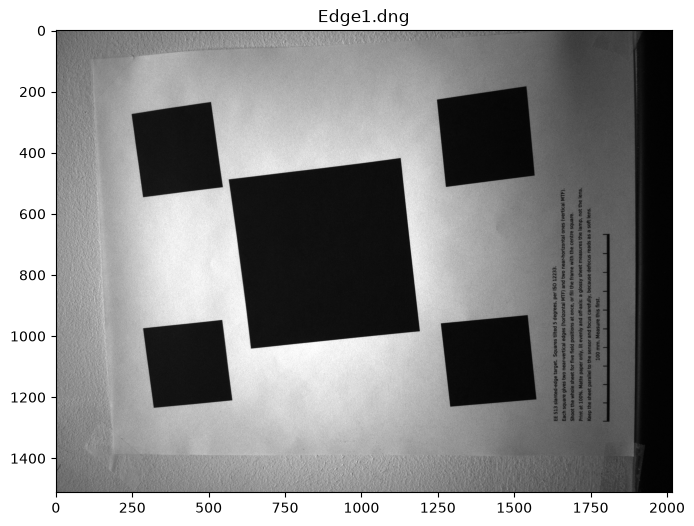

In [71]:
Green_capture_list = []   # raw green values (DN), black level not yet subtracted
Linear_list = []          # black-subtracted, linear in scene radiance

for path in my_capture_series:
    with rawpy.imread(path) as raw:
        mosaic = raw.raw_image_visible.astype(np.float32)
        colors = raw.raw_colors_visible

        # Find where the first green pixel sits in the 2x2 Bayer tile (color index 1 = G)
        pattern = colors[:2, :2]
        r, c = np.argwhere(pattern == 1)[0]

        green = mosaic[r::2, c::2]                  # one green channel, half-res
        black = raw.black_level_per_channel[1]      # black level for green

    Green_capture_list.append(green)
    Linear_list.append(green - black)

    print(f"{os.path.basename(path)}: black={black}, "
          f"min={green.min():.0f}, max={green.max():.0f}")

# view the first image
img = Linear_list[0]

plt.figure(figsize=(8, 6))
plt.imshow(img, cmap="gray", vmin=0, vmax=np.percentile(img, 99.5))
#plt.colorbar(label="Linear DN (black-subtracted)")
plt.title(os.path.basename(my_capture_series[0]))
plt.axis("on")
plt.show()


I think it is asking which of the two green pixels in each mosaic 2x2 we select and why? I maybe missing something but I think they should be very similar and I can't think of a physical reason to pick one over the other. I think probably being consistant and always picking the same one is more important, so therefore I alwats picked the green pixel from the first position of the 2x2. For the black level I thought it would be important to always pick the one that corresponds to the pixel that we picked so I also always did the first one. 

15. Measure MTF50 on the central square of the target in each of your captures, and report the mean and standard deviation across them.
Deliverable: MTF50 as mean ± standard deviation, in cycles per micrometer and in cycles per green-plane pixel.

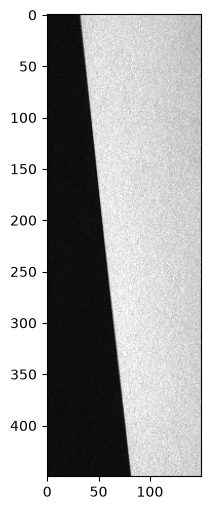

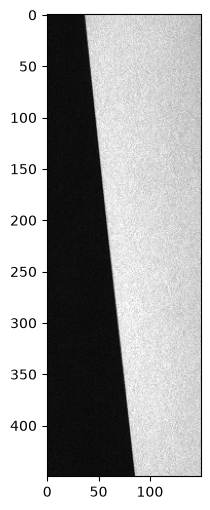

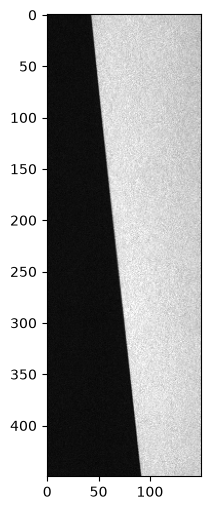

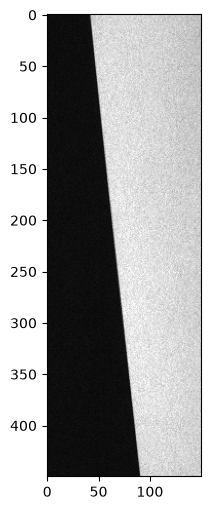

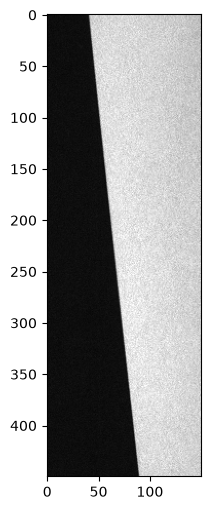

MTF50 per capture: [0.3407921  0.32327345 0.32178606 0.31381622 0.32084396]
Mean = 0.32410235799763165 ± 0.010012760515803455 cycles per green pixel


In [118]:
MTF50_list = []
freq_list, mtf_list = [], []

for img in Linear_list:
    #rows,cols = img.shape
    # crop image to central square edge
    st_row = 450
    ed_row = 900
    st_col = 1100
    ed_col = 1250
    img_crop = img[st_row:ed_row, st_col:ed_col]
    plt.figure(figsize=(8, 6))
    plt.imshow(img_crop, cmap="gray", vmin=0, vmax=np.percentile(img, 99.5))
    plt.axis("on")
    plt.show()

    # calculate the MTF for each time through the loop (each picture)
    img = img_crop
    # 2. find edges
    edge_rows, edge_cols = FindEdges(img)

    # 3. fit a line through that edge points
    slope, intercept, _, _ = theilslopes(edge_cols, edge_rows) # use edge points for the fit line 
    fitted_cols = slope * edge_rows + intercept
    yy, xx = np.indices(img_crop.shape, dtype=float)

    distance = (
        xx - slope * yy - intercept
    ) / np.sqrt(1 + slope**2)
    
    # Oversampling factor: 4 means 0.25 pixel per bin.
    oversampling = 4
    bin_width = 1.0 / oversampling
    
    # Keep the full available distance range.
    d_min = np.floor(distance.min() / bin_width) * bin_width
    d_max = np.ceil(distance.max() / bin_width) * bin_width
    
    bin_edges = np.arange(
        d_min, d_max + bin_width * 1.01, bin_width
    )
    
    # Bin centers.
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
    
    # Average image intensity within each distance bin.
    bin_index = np.digitize(distance.ravel(), bin_edges) - 1
    
    valid = (
        (bin_index >= 0) &
        (bin_index < len(bin_centers))
    )
    
    intensity_sum = np.bincount(
        bin_index[valid],
        weights=img.ravel()[valid],
        minlength=len(bin_centers)
    )
    
    pixel_count = np.bincount(
        bin_index[valid],
        minlength=len(bin_centers)
    )
    
    esf = np.full(len(bin_centers), np.nan)
    occupied = pixel_count > 0
    esf[occupied] = intensity_sum[occupied] / pixel_count[occupied]
    
    # Remove empty bins, if any.
    esf = esf[occupied]
    esf_x = bin_centers[occupied]
    
    # 5. differentiate the edge spread function to get the line spread function
    # Estimate the edge center from the steepest part of the ESF
    edge_center = esf_x[np.argmax(np.abs(np.gradient(esf, esf_x)))]
    
    # Restrict the ESF to a region around the edge
    # The default is half the smaller image dimension on either side
    half_width = min(nrows, ncols) / 2
    roi = np.abs(esf_x - edge_center) <= half_width
    
    esf_roi_x = esf_x[roi]
    esf_roi = esf[roi]
    
    # Fill any remaining gaps by interpolation
    finite = np.isfinite(esf_roi)
    esf_roi = np.interp(
        esf_roi_x,
        esf_roi_x[finite],
        esf_roi[finite]
    )
    
    # LSF = derivative of ESF
    lsf = np.gradient(esf_roi, bin_width)
    
    # Window: Apply a Hann window to the LSF
    # This reduces spectral leakage from finite profile length
    window = windows.hann(len(lsf), sym=True)
    lsf_windowed = lsf * window
    
    # 6. Take the fourier trandform of the LTF and keep the amplitude part (the MTF)
    # rember: normalize to 1 at DC
    
    # Zero-padding interpolates the displayed frequency curve;
    # it does not improve the underlying measurement resolution.
    n_fft = 8 * len(lsf_windowed)
    
    fft_lsf = np.fft.rfft(lsf_windowed, n=n_fft)
    mtf = np.abs(fft_lsf)
    
    # Frequency axis in cycles per pixel.
    freq = np.fft.rfftfreq(n_fft, d=bin_width)
    
    # Normalize so that MTF(0) = 1.
    if mtf[0] > 0:
        mtf /= mtf[0]
    
    # Only display frequencies up to the original image Nyquist limit.
    nyquist = 0.6 # actually keep more than up to nyquist
    keep = freq <= nyquist
    
    freq_plot = freq[keep]
    mtf_plot = mtf[keep]

    # get the mtf50:
    # Find the first frequency where MTF <= 0.5
    crossings = np.where(mtf_plot <= 0.5)[0]
    
    if len(crossings) == 0:
        mtf50 = np.nan
        print("MTF50 was not reached in the measured frequency range.")
    elif crossings[0] == 0:
        mtf50 = freq_plot[0]
    else:
        # Linear interpolation between adjacent samples
        i = crossings[0]
    
        f1, f2 = freq_plot[i - 1], freq_plot[i]
        m1, m2 = mtf_plot[i - 1], mtf_plot[i]
    
        mtf50 = f1 + (0.5 - m1) * (f2 - f1) / (m2 - m1)
    MTF50_list.append(mtf50)
    freq_list.append(freq_plot)   # cycles per green-plane pixel
    mtf_list.append(mtf_plot)
    
# the mean and sd of the mtf50 of the five captures
mtf50_arr = np.array(MTF50_list)
print("MTF50 per capture:", mtf50_arr)
print("Mean = " + str(np.nanmean(mtf50_arr)) + " ± " + str( np.nanstd(mtf50_arr, ddof=1)) + " cycles per green pixel")

In [119]:
# can we comvert this to cyles/um

PIXEL_PITCH_UM = 2.576         # i think we need the pitch of the camera that we calculated above:
green_pitch_um = 2 * PIXEL_PITCH_UM   # physical spacing of one green-plane sample

mtf50_arr = np.array(MTF50_list)                 # cycles per green-plane pixel
mtf50_cyc_per_um = mtf50_arr / green_pitch_um    # cycles per micrometer

def report(label, arr, unit, fmt=".4f"):
    print(f"{label}: mean = {np.nanmean(arr):{fmt}}, "
          f"± {np.nanstd(arr, ddof=1):{fmt}} {unit}")

print("MTF50 each capture (cycles/green px):", np.round(mtf50_arr, 4))
print("MTF50 each capture (cycles/um):      ", np.round(mtf50_cyc_per_um, 4))
report("MTF50", mtf50_arr, "cycles/green-plane pixel")
report("MTF50", mtf50_cyc_per_um, "cycles/µm", fmt=".5f")


MTF50 each capture (cycles/green px): [0.3408 0.3233 0.3218 0.3138 0.3208]
MTF50 each capture (cycles/um):       [0.0661 0.0627 0.0625 0.0609 0.0623]
MTF50: mean = 0.3241, ± 0.0100 cycles/green-plane pixel
MTF50: mean = 0.06291, ± 0.00194 cycles/µm


16. Compare your measurement against your prediction by reporting the predicted modulation at the Nyquist frequency from item 7 alongside the measured value at the same frequency. The prediction accounted for diffraction and the photodiode aperture only. Identify the effects present in the real system that it omitted, state which one you believe dominates, and describe a measurement that would distinguish between them.
Deliverable: Predicted and measured modulation at Nyquist, and a written analysis (4–5 sentences).

From prediction in part 7:

At Nyquist (0.1941 cycles/um = 194.1 cycles/mm):
  MTFd = 0.784, MTFp = 0.900, product = 0.705

In [120]:
green_pitch_um = 2.576          # um per green-plane pixel
nu_target = 0.1941              # cycles/um (green-plane Nyquist)

mtf_at_nyq = []
for f, m in zip(freq_list, mtf_list):
    f_um = f / green_pitch_um               # cycles/px -> cycles/um
    mtf_at_nyq.append(np.interp(nu_target, f_um, m))

mtf_at_nyq = np.array(mtf_at_nyq)
print("MTF at Nyquist per capture:", np.round(mtf_at_nyq, 4))
print(f"Mean = {mtf_at_nyq.mean():.4f}, SD = {mtf_at_nyq.std(ddof=1):.4f}")

MTF at Nyquist per capture: [0.2122 0.2246 0.1795 0.1994 0.1905]
Mean = 0.2012, SD = 0.0177


The measured and predicted values are fairly far apart. THe measured ones are smaller than the predicted option, so this means that we measure lower modualtion (contrast) at the same nyquist frequency than in the ideal calculated case. The predicted did not take into account lens aberation. I actually think that my camera lens may have large defocus aberation (I dropped my phone a while back and it has never quire focused correctly sense then). There are also othe aberations that would happen because we do not have perfect lenses. I think maybe movement between captures would cause some of the error, I set my phone up on some book but this still not as stable or repeatable as a tripod or mount. To check the effect of the de focus, could we do a series of captures with increasingly worse focus, if that does not effect the value much than we should look to another cause. Other aberations should be worse at the image edges (edge of the lens) so if we calculated the modulation at nyquist for a series of tilted edges at the edge of the field of view we should see worse performance if there are aberations present.

### Reflections

17. What did you learn from this assignment?
Deliverable: A brief written response.

One thing I learned alot about was the MTF, for whatever reason I think I didn;t get alot from the last lecture so going through the theoretical calcualtions as well as from our capture helped. I also think this assignment helped me think about what in the camera system would effect the redolution.

18. What questions, if any, do you have for me after completing this assignment?
Deliverable: A brief written response.

Even though I used a raw capture app for the pictures is there any processing that may be happening that could effect our results? How would we check this?

AI usage:

As in the last assignment I used ai tools to help write the scripts for this project ( mostly claude), I also found the examples on the class canva to be a helpful referene. It was also helpful to compare those examples to the AI tool outputs. Furthermore, the built in validatios against known results in this assignment we helpful to confirm we were on the correct track. I see how those types of validations are important going forward. 

